## **Imports**

In [1]:
# These lines import the NumPy and Pandas libraries to handle math and data tables.
# They allow the script to store and manipulate weather data efficiently.
import numpy as np
import pandas as pd

# This line imports a tool used to create visual charts and graphs.
# It is necessary for plotting the temperature trends and error results later on.
import matplotlib.pyplot as plt

#These functions are used to calculate how much the predictions differ from actual weather.
# They provide specific scores that tell us if the model is performing well or poorly (GeeksforGeeks, 2024b).
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# This imports the machine learning algorithm that will be trained to forecast the weather.
# It uses a series of decision trees to find patterns in the data.
from xgboost import XGBRegressor

## **Load Dataset**


In [2]:
# These aid in opening and storing the .csv files in the program.
# This provides raw historical weather information for this activity.
df_train = pd.read_csv("DailyDelhiClimateTrain.csv")
df_test = pd.read_csv("DailyDelhiClimateTest.csv")

# This converts the date text into a format that Python understands as actual time.
# It ensures that the computer can sort the days in the correct order.
df_train["date"] = pd.to_datetime(df_train["date"])
df_test["date"]  = pd.to_datetime(df_test["date"])

# This line removes any overlapping days that might exist between the two datasets.
# It ensures that the training data ends exactly before the test data begins.
df_train = df_train[df_train["date"] < df_test["date"].min()].copy()

# This combines the training and testing records into one continuous master list.
# The head command shows the first few rows to verify the data looks correct.
df = pd.concat([df_train, df_test], axis=0)
df.head()

,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


## **Data Preprocessing**


In [3]:
# This counts how many empty or missing values are in each column of the data.
# It helps the user see if there are gaps in the weather recordings.
df.isna().sum()

,0
date,0
meantemp,0
humidity,0
wind_speed,0
meanpressure,0


In [4]:
# The script confirms the dates are formatted correctly and sorts the rows from oldest to newest.
# Sorting is required for time-series data to maintain the correct sequence of events.
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

# This combines rows that have the same date by calculating their average values.
# It ensures that every day in the dataset is unique.
df = df.groupby("date", as_index=False).mean(numeric_only=True)

# These variables define which weather factor to predict and which factors to use as clues.
# The "meantemp" is the target variable the model is trying to solve for.
TARGET = "meantemp"
EXOG = ["humidity", "wind_speed", "meanpressure"]
num_cols = [TARGET] + EXOG

# This identifies air pressure readings that are too high or too low to be real.
# It removes these errors so they do not confuse the machine learning model.
df["meanpressure"] = df["meanpressure"].mask(
    (df["meanpressure"] < 900) | (df["meanpressure"] > 1100)
)

# This fills in the missing or removed pressure values by looking at the values around them.
# It creates a smooth and complete set of data without any gaps.
df["meanpressure"] = df["meanpressure"].interpolate(limit_direction="both")

In [5]:
# This creates the answer key by moving tomorrow's temperature onto today's row.
# The last row is removed because there is no known "tomorrow" for the final day.
df["y"] = df[TARGET].shift(-1)
df = df.iloc[:-1].copy()

## **Data Exploration**


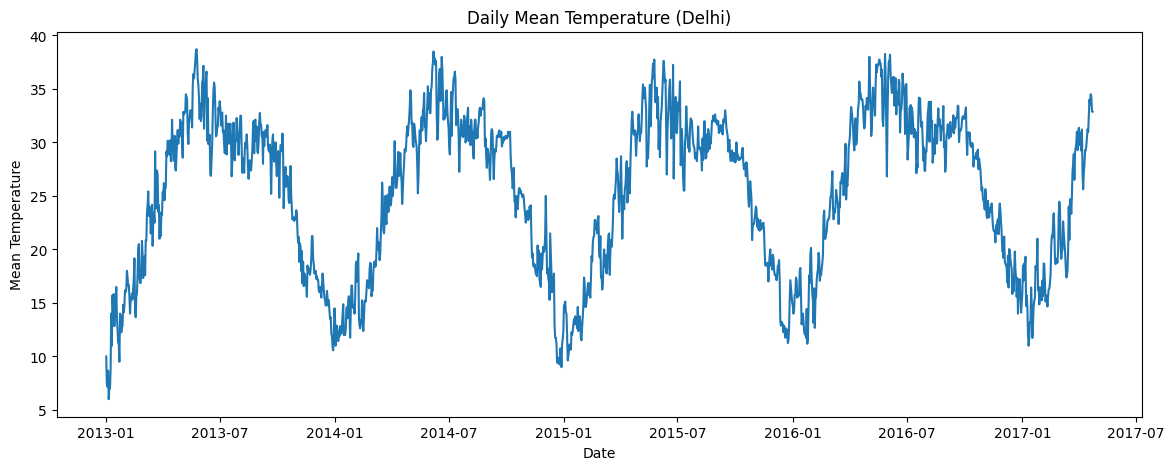

In [6]:
# This block creates a large line graph to show how the temperature fluctuated over time.
# It helps visualize the seasonal ups and downs throughout the years.
plt.figure(figsize=(14,5))
plt.plot(df["date"], df[TARGET])
plt.title("Daily Mean Temperature (Delhi)")
plt.xlabel("Date")
plt.ylabel("Mean Temperature")
plt.show()

<Figure size 1200x500 with 0 Axes>

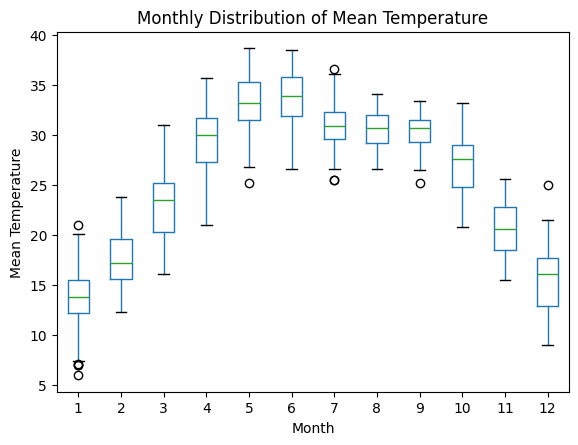

In [7]:
# A temporary dataset is created to pull the specific month out of every date entry.
# This makes it possible to group temperatures together to see seasonal trends during the visual analysis.
tmp = df.copy()
tmp["month"] = tmp["date"].dt.month

# This creates a boxplot showing the temperature range for every month.
# It allows you to see the typical heat or cold patterns for each specific time of year.
plt.figure(figsize=(12,5))
tmp.boxplot(column=TARGET, by="month", grid=False)
plt.suptitle("")
plt.title("Monthly Distribution of Mean Temperature")
plt.xlabel("Month")
plt.ylabel("Mean Temperature")
plt.show()

## **Data Split**


In [8]:
# This finds the last date available in the original training file.
# This date is used as a boundary to separate the data correctly.
train_max_date = pd.to_datetime(df_train["date"]).max()

# The script splits the full dataset into one part for training and one part for testing.
# This ensures the model is tested on data it has never seen before.
train_df = df[df["date"] <= train_max_date].copy()
test_df  = df[df["date"] >  train_max_date].copy()

# Split train into train/val chronologically (last 20% as validation)
val_frac = 0.2
split_idx = int(len(train_df) * (1 - val_frac))

# These lines divide the training data into two chronological pieces based on the 80/20 split calculated earlier.
# The first part is used for building the model, and the second is used for tuning it.
train_part = train_df.iloc[:split_idx].copy()
val_part   = train_df.iloc[split_idx:].copy()

# These print statements display the start and end dates for every single data group in the project.
# This confirms that there are no gaps or overlaps in the timeline of the weather records.
print("Train-part:", train_part["date"].min(), "to", train_part["date"].max(), "|", len(train_part))
print("Val-part  :", val_part["date"].min(),   "to", val_part["date"].max(),   "|", len(val_part))
print("Test      :", test_df["date"].min(),    "to", test_df["date"].max(),    "|", len(test_df))

Train-part: 2013-01-01 00:00:00 to 2016-03-13 00:00:00 | 1168
Val-part  : 2016-03-14 00:00:00 to 2016-12-31 00:00:00 | 293
Test      : 2017-01-01 00:00:00 to 2017-04-23 00:00:00 | 113


## **Feature Engineering**

In [9]:
# This starts a function that creates new information to help the model learn.
# It makes a copy of the data to avoid changing the original information.
def make_features(d):
    d = d.copy()

    # These lines pull the day, month, and year-day out of the date.
    # This helps the model recognize patterns that happen on certain days of the week or year.
    d["dow"] = d["date"].dt.dayofweek
    d["month"] = d["date"].dt.month
    d["dayofyear"] = d["date"].dt.dayofyear

    # These lines convert the day of the year into a circular wave format.
    # It helps the model understand that January 1st and December 31st are close together.
    d["doy_sin"] = np.sin(2 * np.pi * d["dayofyear"] / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * d["dayofyear"] / 365.25)

    d["dow_sin"] = np.sin(2 * np.pi * d["dow"] / 7.0)
    d["dow_cos"] = np.cos(2 * np.pi * d["dow"] / 7.0)

    # This loop tells the model what the temperature was on previous days and weeks.
    # Looking at past temperatures is a great way to predict the next day.
    for lag in [1, 2, 3, 7, 14, 30, 365]:
        d[f"{TARGET}_lag{lag}"] = d[TARGET].shift(lag)

    # This calculates the average and spread of temperatures over the last week or month.
    # It shows the model the recent weather trends leading up to today.
    for w in [7, 14, 30, 365]:
        d[f"{TARGET}_roll_mean{w}"] = d[TARGET].shift(1).rolling(w).mean()
        d[f"{TARGET}_roll_std{w}"]  = d[TARGET].shift(1).rolling(w).std()

    # This loop goes through external factors like humidity and wind speed to create historical record columns.
    # It helps the model see if yesterday's wind or humidity affects tomorrow's temperature.
    for c in EXOG:
        for lag in [1, 2, 7]:
            d[f"{c}_lag{lag}"] = d[c].shift(lag)

    # This line identifies the temperature for the very next day and labels it as the target variable.
    # It tells the model exactly what the "correct answer" is for every row of data.
    d["y"] = d[TARGET].shift(-1)

    # The script calculates the change in temperature and removes any rows with missing info.
    # The finished set of features is then sent back to be used.
    d["delta"] = d["y"] - d[TARGET]
    d = d.dropna().copy()
    return d



In [10]:
# This line runs the feature engineering function on the training data to create lags and rolling averages.
# It transforms the raw numbers into a format the machine learning model can actually learn from.
train_fe = make_features(train_part)

# This line runs the feature engineering function on the training data to create lags and rolling averages.
# It transforms the raw numbers into a format the machine learning model can actually learn from.
val_context  = pd.concat([train_part.tail(400), val_part], ignore_index=True)
test_context = pd.concat([train_df.tail(400),  test_df],  ignore_index=True)

# The script applies the feature creation function to these new combined datasets.
# This ensures that the validation and test data have the exact same columns as the training data.
val_fe  = make_features(val_context)
test_fe = make_features(test_context)

# This filter removes the extra "context" rows once the calculations for the lags are finished.
# It makes sure we are only evaluating the model on the specific dates we originally intended to test.
val_fe  = val_fe[val_fe["date"].isin(val_part["date"])]
test_fe = test_fe[test_fe["date"].isin(test_df["date"])]

# This line creates a list of all column names that the model will use as inputs for its predictions.
# It specifically leaves out the date and the answer columns so the model doesn't "cheat."
FEATURES = [c for c in train_fe.columns if c not in ["date", "y", "delta"]]

# The data is split into "X" values, which are the inputs, and "y" values, which are the temperature changes to predict.
# This separation is the standard format required to train most machine learning algorithms.
X_train, y_train = train_fe[FEATURES], train_fe["delta"]
X_val,   y_val   = val_fe[FEATURES],   val_fe["delta"]
X_test,  y_test  = test_fe[FEATURES],  test_fe["delta"]

# This command prints out the dimensions of the final datasets to show how many rows and features were created.
# It allows the user to verify that the data splitting and cleaning worked as expected.
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (802, 35) Val: (292, 35) Test: (112, 35)


## **Data Modeling**



In [11]:
# This block sets up the rules for the XGBoost forecasting model.
# It determines how fast the model learns and when it should stop training.
xgb = XGBRegressor(
    n_estimators=5000,
    learning_rate=0.02,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    eval_metric="rmse",
    early_stopping_rounds=100,
)

# This command makes the model study the training data to find patterns.
# It uses the validation data to make sure it isn't making too many mistakes.
xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# The model makes its final guesses on how much the temperature will change.
# These predictions are made for both the validation and the testing periods.
pred_delta_val  = xgb.predict(X_val)
pred_delta_test = xgb.predict(X_test)

# The predicted change is added back to today's temperature to get the final forecast.
# This gives us the actual temperature we expect to see tomorrow.
pred_val  = val_fe[TARGET].values + pred_delta_val
pred_test = test_fe[TARGET].values + pred_delta_test

## **Evaluation**


In [12]:
# This function calculates the average number of degrees the model's predictions are away from the truth.
# It is a standard way to measure the size of errors in temperature forecasting.
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# These lines extract the real temperatures that actually happened during the validation and test timeframes.
# These act as the ground truth to which the model's guesses will be compared.
val_true  = val_fe["y"].values
test_true = test_fe["y"].values

# This prints the error scores for the XGBoost model using the validation data.
# It shows exactly how accurate the model was during the intermediate checking phase.
print("\nXGBOOST VAL   MAE:", mean_absolute_error(val_true, pred_val),
      "RMSE:", rmse(val_true, pred_val))

print("XGBOOST TEST  MAE:", mean_absolute_error(test_true, pred_test),
      "RMSE:", rmse(test_true, pred_test))

# These lines create a "naive" forecast by assuming tomorrow will be exactly the same as today.
# This baseline acts as a benchmark to see if the machine learning model is actually useful.
baseline_val  = val_fe[TARGET].values
baseline_test = test_fe[TARGET].values

# These final print commands display the basic error scores for the baseline model directly in the console.
# This serves as a quick final check to verify the most important accuracy numbers for the project.
print("BASELINE VAL  MAE:", mean_absolute_error(val_true, baseline_val),
      "RMSE:", rmse(val_true, baseline_val))

print("BASELINE TEST MAE:", mean_absolute_error(test_true, baseline_test),
      "RMSE:", rmse(test_true, baseline_test))


XGBOOST VAL   MAE: 1.2080849485537841 RMSE: 1.5827674661669033
XGBOOST TEST  MAE: 1.3062629932974699 RMSE: 1.6828898223918098
BASELINE VAL  MAE: 1.2462525917530942 RMSE: 1.661339222930537
BASELINE TEST MAE: 1.3215863197485713 RMSE: 1.6954479196654564


In [13]:
# This function bundles four different scoring methods into one tool to judge the model's accuracy.
# It calculates the average error, the percentage error, and how well the model fits the overall data trend.
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, mape, r2

# The script prepares an empty list to store scores and extracts the actual temperature values for comparison.
# It also sets up the "baseline" values, which are used as a simple yardstick to measure the model's improvement.
rows = []

val_true  = val_fe["y"].values
test_true = test_fe["y"].values

baseline_val  = val_fe[TARGET].values
baseline_test = test_fe[TARGET].values

# These lines calculate the performance scores for the simple "yesterday equals tomorrow" guess.
# The results are saved into the row list so they can be compared against the smarter machine learning model.
mae, rmse_v, mape, r2 = regression_metrics(val_true, baseline_val)
rows.append(["Baseline (Val)", mae, rmse_v, mape, r2])

mae, rmse_t, mape, r2 = regression_metrics(test_true, baseline_test)
rows.append(["Baseline (Test)", mae, rmse_t, mape, r2])

# This block calculates the final accuracy scores for the XGBoost model on both validation and test data.
# These numbers tell you exactly how much better (or worse) the model is compared to the simple baseline.
mae, rmse_v, mape, r2 = regression_metrics(val_true, pred_val)
rows.append(["XGBoost (Val)", mae, rmse_v, mape, r2])

mae, rmse_t, mape, r2 = regression_metrics(test_true, pred_test)
rows.append(["XGBoost (Test)", mae, rmse_t, mape, r2])

# This creates a clean summary table that organizes all the scores into readable columns.
# It formats the numbers to a few decimal places so you can easily compare the different models at a glance.
metrics_df = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "MAPE (%)", "R²"])
metrics_df.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "MAPE (%)":"{:.2f}", "R²":"{:.3f}"})

,Model,MAE,RMSE,MAPE (%),R²
0,Baseline (Val),1.246,1.661,4.49,0.911
1,Baseline (Test),1.322,1.695,6.69,0.927
2,XGBoost (Val),1.208,1.583,4.35,0.919
3,XGBoost (Test),1.306,1.683,6.64,0.928


## Result Plots


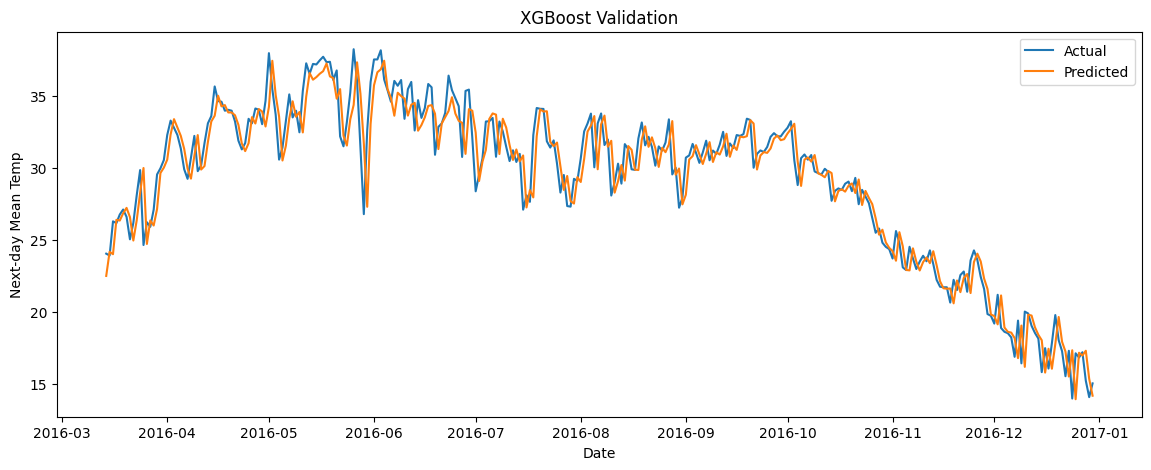

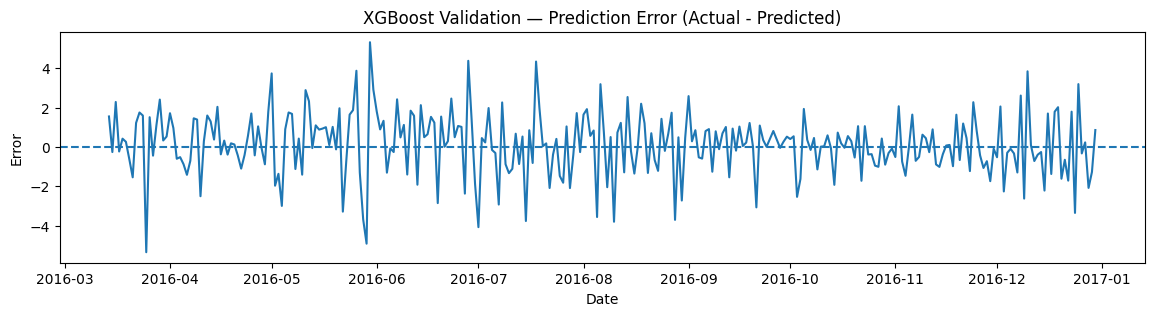

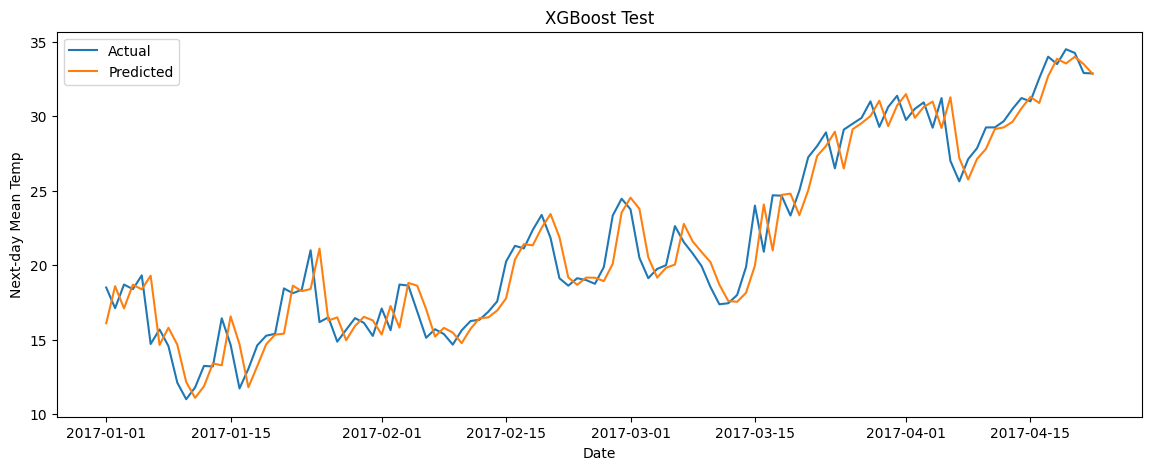

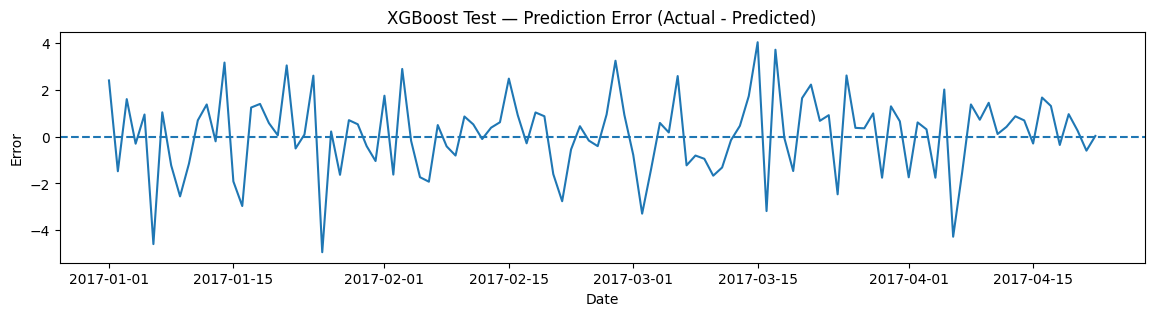

In [14]:
# This function is designed to draw two different graphs: one for the temperature forecast and one for the errors.
# It provides a visual way to see where the model's predictions are most and least accurate.
def plot_pred_with_error(dates, y_true, y_pred, title):
    err = y_true - y_pred

    # This block creates a visual comparison graph showing the real temperatures against the model's predicted values.
    # It includes labels and a legend so you can easily see how closely the two lines follow each other over time.
    plt.figure(figsize=(14,5))
    plt.plot(dates, y_true, label="Actual")
    plt.plot(dates, y_pred, label="Predicted")
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Next-day Mean Temp")
    plt.legend()
    plt.show()

    # This section generates a secondary graph specifically to show the gap between the actual and predicted temperatures.
    # The dashed horizontal line represents a perfect guess, helping you see where the model was too high or too low.
    plt.figure(figsize=(14,3))
    plt.plot(dates, err)
    plt.axhline(0, linestyle="--")
    plt.title(title + " — Prediction Error (Actual - Predicted)")
    plt.xlabel("Date")
    plt.ylabel("Error")
    plt.show()

# These commands call the plotting function to display the final results for both the validation and test sets.
# They allow you to see the actual vs. predicted lines side-by-side on a timeline.
plot_pred_with_error(val_fe["date"], val_true, pred_val, "XGBoost Validation")
plot_pred_with_error(test_fe["date"], test_true, pred_test, "XGBoost Test")

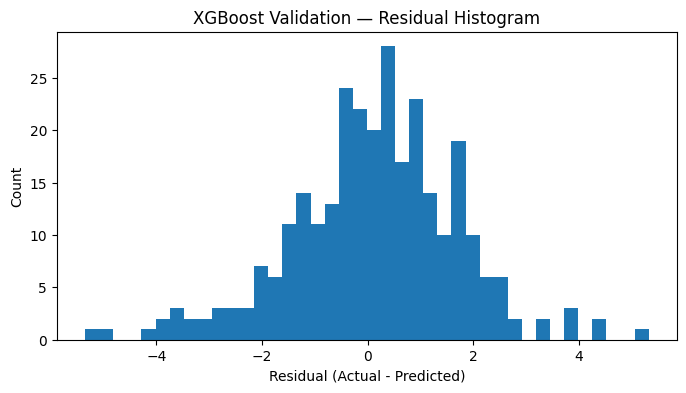

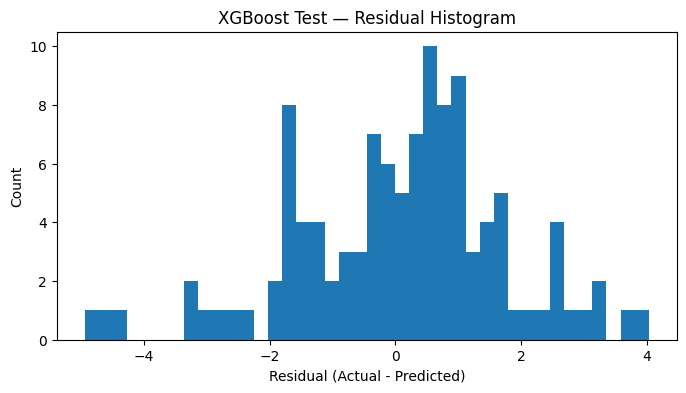

In [15]:
# This function creates a bar chart showing the frequency of different error sizes.
# It helps identify if the model is biased toward guessing too high or too low.
def residual_hist(y_true, y_pred, title):
    resid = y_true - y_pred
    plt.figure(figsize=(8,4))
    plt.hist(resid, bins=40)
    plt.title(title + " — Residual Histogram")
    plt.xlabel("Residual (Actual - Predicted)")
    plt.ylabel("Count")
    plt.show()

# The final lines display the error histograms for the validation and testing phases.
# You want to see most errors clustered around zero, which means the model is usually very accurate.
residual_hist(val_true, pred_val, "XGBoost Validation")
residual_hist(test_true, pred_test, "XGBoost Test")

- - -
# **Discussion**
- - -


## **Dataset Background**

The Delhi Climate dataset provides a practical and high-signal setting for urban environmental monitoring because it captures day-by-day fluctuations that are driven by both slow seasonal cycles and short-term weather disturbances (Weather Undergroud API, 2019). In an urban context, these dynamics matter because temperature is not only a comfort indicator, but also a proxy for energy demand, heat-risk exposure, and the interaction of meteorological variables such as humidity, wind movement, and atmospheric pressure. This makes the dataset well-suited for time-series forecasting, where the goal is not merely to fit a trend line but to learn repeatable temporal structure while remaining responsive to sudden day-to-day shifts that can occur around transitions between seasons or during localized weather events.

## **Data Preprocessing**

The dataset was first standardized into a single chronological timeline by parsing the date column into a proper datetime type, sorting by time, and resolving structural issues caused by merging separate train and test files. Overlapping dates were removed to ensure the training period ends strictly before the test period begins, which was chosen due to the need to prevent temporal leakage where identical timestamps could appear in both partitions. Duplicate dates were then consolidated into one (1) record per day through aggregation, which indicates that lag and rolling computations are built on a stable daily index rather than conflicting repeated entries.

Cleaning focused on correcting only anomalies that were clearly measurement-driven rather than environmentally meaningful. Meanpressure values below 900 or above 1100 were masked and replaced through smooth interpolation, which was chosen due to these extremes being physically implausible in this context and capable of distorting the learning process if left untreated. In contrast, other outliers were retained as meaningful events, which indicates an intentional decision to preserve real short-term volatility that the forecasting model must learn to handle rather than smoothing the series into an unrealistic pattern.

A strict chronological split was applied, with the final twenty (20) percent of the training-era timeline reserved for validation and the provided test-era timeline reserved for true evaluation. This was chosen due to time-series forecasting requiring causal ordering, where future information must never influence training. Feature engineering then encoded seasonality and temporal memory through sine/cosine cyclical features for annual and weekly phase, plus multi-scale lags of one (1), two (2), three (3), seven (7), fourteen (14), thirty (30), and three hundred sixty-five (365) days and rolling statistics over seven (7), fourteen (14), thirty (30), and three hundred sixty-five (365) days computed using a one (1) day shift, which indicates that all derived predictors rely strictly on past information.


## **Data Modeling**

The forecasting model is implemented using an XGBoost Regressor, which is a gradient-boosted decision tree ensemble optimized for tabular feature spaces (GeeksforGeeks, 2024). This was chosen due to the feature design: once lagged values, rolling statistics, and cyclical encodings are created, the problem becomes a structured regression task where non-linear interactions matter (XGBoost Documentation, 2026). Temperature dynamics can depend on conditional thresholds such as “high humidity combined with low wind speed” or “particular seasonal phase combined with recent rolling volatility,” and tree-based boosting is well-suited to learning such interactions without requiring explicit parametric assumptions.

The parameterization emphasizes stable generalization rather than aggressive fitting. A large cap of five thousand (5000) estimators paired with a small learning rate of 0.02 encourages the model to build predictive structure gradually, which indicates a preference for many small corrective steps instead of a few large ones that may overfit. The max depth of four (4) and the minimum child weight of five (5) constrain tree complexity, which was chosen due to the risk that high-dimensional lag features can allow overly specific splits that memorize noise. Subsampling (0.8) and column sampling (0.8) further regularize training by injecting randomness into each boosting round, which indicates that the model is less likely to lock onto spurious correlations that appear only in a narrow slice of time.

Early stopping is integrated directly into training using the chronological validation segment and a patience of one hundred (100) rounds. This was chosen due to the iterative nature of boosting; as more trees are added, the model can move from learning general structure to fitting residual noise. Early stopping halts training at the point where validation error no longer improves, which indicates a data-driven selection of ensemble size that balances bias and variance. In a time-series context, this matters because distribution drift across seasons can cause later trees to over-specialize to patterns that do not hold in the forward horizon.

Finally, the delta strategy is operationalized during inference by reconstructing the final temperature forecast as today’s observed temperature plus the predicted delta. This highlights an important modeling alignment: the learner is trained to estimate “movement,” but the evaluation is conducted on the real next-day temperature target, which indicates that performance comparisons against the persistence baseline remain fair and directly interpretable in temperature units.

## **Results and Visualization**

The exploratory figures establish that the forecasting problem is both learnable and structurally complex. The Daily Mean Temperature plot exhibits a repeating annual oscillation with pronounced peaks and troughs, which highlights strong seasonality that indicates calendar position is a dominant explanatory factor rather than a minor covariate. This seasonal structure is reinforced by the Monthly Distribution boxplot, where the medians increase as the series transitions into the warmer months and then decline toward the cooler months, indicating that month-level regimes are statistically distinct and not interchangeable. At the same time, the spread within several months and the presence of outliers show that variability persists even within the same seasonal phase, which indicates that the model must learn more than a smooth seasonal template and must remain responsive to short-term disturbances superimposed on the annual cycle.

Model performance confirms that the engineered feature space allowed XGBoost to outperform a persistence-style baseline while maintaining stable generalization from validation to test. On the validation segment, the XGBoost model achieved a **mean absolute error of 1.2080849485537841** and a **root mean squared error of 1.5827674661669033**, while the baseline recorded a **mean absolute error of 1.2462525917530942** and a **root mean squared error of 1.661339222930537** (Chugh, 2020).  This highlights that the delta-target strategy and lagged multi-scale features provided predictive value beyond simply carrying forward today’s temperature, which indicates that the model learned conditions associated with directional change rather than merely reproducing persistence. On the test segment, XGBoost sustained this advantage with a **mean absolute error of 1.3062629932974699** and a **root mean squared error of 1.6828898223918098**, compared to the baseline **mean absolute error of 1.3215863197485713** and **root mean squared error of 1.695447919665456**. This indicates that the improvement was not restricted to the validation window and that the learned relationships generalized into genuinely unseen future days.

The Actual versus Predicted overlays visually justify these error statistics by showing how closely the model tracked the observed next-day temperature trajectory. In the XGBoost Validation plot, the predicted line follows the actual series across both gradual seasonal movement and smaller oscillations, which indicates that the learner is not merely producing a smoothed seasonal curve but is responding to short-horizon changes captured by lag and rolling features. In the XGBoost Test plot, the predicted series continues to shadow the actual pattern and reproduces most turning points with limited lag, which highlights that the model is leveraging both immediate memory and seasonal phase information to anticipate near-term direction. Where deviations occur, they typically appear around sharper inflection points or brief spikes, which indicates that the remaining error is concentrated in event-like days that are inherently harder to infer from prior values alone.

Residual diagnostics further support the interpretation that errors are largely well-behaved rather than systematically biased. The validation residual histogram concentrates around zero, indicating that most errors are small and centered, while the test residual histogram retains a similar center with a slightly wider spread, which is expected under forward generalization where the test window may contain conditions not perfectly represented in earlier periods. The prediction error time series for both validation and test oscillates around the zero line without sustained drift, which indicates that the model does not consistently overpredict or underpredict across extended intervals. Instead, the error spikes are intermittent and transient, which highlights that the model’s primary limitation is capturing abrupt, localized departures rather than maintaining the broader structure of the series. Collectively, these visual patterns align with the MAE and RMSE results by showing that the model’s typical day-to-day error remains modest while the larger residuals occur in relatively sparse, high-variance moments.

## **Conclusion**

The Delhi Climate time series demonstrates a highly forecastable seasonal backbone combined with irregular short-term variability, and the delta-targeted XGBoost pipeline leveraged this structure through chronological splitting, careful cleaning, cyclical encodings, and multi-scale lag and rolling features to learn next-day temperature movement beyond persistence. The resulting performance, reflected by validation **MAE of 1.2080849485537841** and **RMSE of 1.5827674661669033** and test **MAE of 1.3062629932974699** and **RMSE of 1.6828898223918098**, indicates stable generalization and consistent improvement over the baseline, while the Actual versus Predicted overlays and centered residual distributions confirm that most errors are small, largely unbiased, and primarily concentrated around abrupt inflection events rather than systematic model drift.

- - -
# **References**

* Chugh, A. (2020, December 8). MAE, MSE, RMSE, Coefficient of Determination, Adjusted R Squared — Which Metric is Better? Medium. https://medium.com/analytics-vidhya/mae-mse-rmse-coefficient-of-determination-adjusted-r-squared-which-metric-is-better-cd0326a5697e
* GeeksforGeeks. (2024a, April). Time Series Analysis and Forecasting. GeeksforGeeks. https://www.geeksforgeeks.org/machine-learning/time-series-analysis-and-forecasting/
* GeeksforGeeks. (2024b, June 28). Calculating RMSE Using Scikitlearn. GeeksforGeeks. https://www.geeksforgeeks.org/machine-learning/calculating-rmse-using-scikit-learn/
* Weather Undergroud API. (2019). Daily Climate time series data. Kaggle. https://www.kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data
* XGBoost Documentation. (2026). XGBoost Documentation — xgboost 3.2.0 documentation. Readthedocs.io. https://xgboost.readthedocs.io/en/release_3.2.0/


